# Modelamiento de LGD mediante Regresión Lineal Clásica
## Ajuste OLS, Métricas de Desempeño, Análisis de Significancia y Diagnóstico del Error

Este notebook formaliza el estudio de la **Regresión Lineal Simple y Múltiple** para la estimación de la **LGD (Loss Given Default)** en la cartera de créditos de Lending Club que presentaron incumplimiento (`Charged Off` y `Default`).

### Formulación Teórica del Modelo

Se formula el modelo lineal clásico empleando variables cuantitativas y **variables indicadoras** $I$ (con el Grado `A` y el plazo de `36 meses` como categorías de referencia):

$$
LGD_i = \beta_0 + \beta_1 (funded\_amnt\_k_i) + \beta_2 I_{term60, i} + \sum_{k \in \{B, C, D, E, FG\}} \beta_k I_{grade\_k, i} + \beta_3 \ln(annual\_inc_i) + \beta_4 (dti_i) + \beta_5 (revol\_util_i) + \beta_6 (inq\_6m_i) + \beta_7 (pub\_rec_i) + \beta_8 I_{verified, i} + \varepsilon_i
$$

Donde:
- $\beta_0$: Intercepto o severidad base esperada para el perfil de referencia (Grado A, 36 meses, ingresos no verificados).
- $I_{term60, i}$: Variable indicadora que toma valor $1$ si el plazo es de 60 meses y $0$ si es de 36 meses.
- $I_{grade\_k, i}$: Variables indicadoras para cada grupo de calificación crediticia ($k \in \{B, C, D, E, FG\}$), donde $FG$ es la categoría fusionada respaldada por la prueba de Tukey.
- $I_{verified, i}$: Variable indicadora que toma valor $1$ si los ingresos fueron verificados y $0$ en caso contrario.
- $\varepsilon_i$: Término de perturbación o error aleatorio con supuestos clásicos de Gauss-Markov: $E[\varepsilon_i \mid X_i] = 0$, $Var(\varepsilon_i \mid X_i) = \sigma^2$.

--- 
### 1. Importación de Librerías y Carga de Datos

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelamiento econométrico y estadístico
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import scipy.stats as stats

# Machine Learning para partición y métricas
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Configuración de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

base_dir = Path.cwd()
csv_path = base_dir / 'loan' / 'loan.csv'
if not csv_path.exists():
    csv_path = base_dir / 'loan.csv'

print(f'Cargando datos desde: {csv_path}')

Cargando datos desde: c:\Users\ADMON\Documents\Universidad\Redes Neuronales\Trabajos\trabajo_2\loan\loan.csv


--- 
### 2. Preparación de la Muestra y Construcción de Variables Indicadoras

In [2]:
cols = [
    'loan_status', 'funded_amnt', 'total_rec_prncp', 'recoveries', 'collection_recovery_fee',
    'term', 'grade', 'annual_inc', 'dti', 'revol_util', 'inq_last_6mths', 'pub_rec', 'verification_status'
]

df_raw = pd.read_csv(csv_path, usecols=cols, low_memory=False)

# Filtrar únicamente créditos en incumplimiento
defaults = df_raw[df_raw['loan_status'].isin(['Charged Off', 'Default'])].copy()

# 1. Variable Dependiente: LGD Proxy
defaults['LGD'] = 1 - (defaults['total_rec_prncp'] / defaults['funded_amnt'])

# 2. Variables Indicadoras (I)
# Indicadora de plazo (Base: 36 months)
defaults['I_term60'] = (defaults['term'].str.strip() == '60 months').astype(int)

# Indicadoras de grado (Base: Grado A; Grados F y G agrupados según Tukey)
grade_agrup = defaults['grade'].replace({'G': 'FG', 'F': 'FG'})
for g in ['B', 'C', 'D', 'E', 'FG']:
    defaults[f'I_grade_{g}'] = (grade_agrup == g).astype(int)

# Indicadora de verificación de ingresos (Base: Not Verified)
defaults['I_verified'] = (defaults['verification_status'] != 'Not Verified').astype(int)

# 3. Variables Cuantitativas Ex-Ante
defaults['funded_amnt_k'] = defaults['funded_amnt'] / 1000.0  # Monto en miles de USD
defaults['log_annual_inc'] = np.log1p(defaults['annual_inc'].clip(lower=0))
defaults['revol_util_num'] = defaults['revol_util'].astype(str).str.rstrip('%').astype(float)
defaults['dti_clean'] = defaults['dti']
defaults['inq_6m'] = defaults['inq_last_6mths']
defaults['pub_rec_clean'] = defaults['pub_rec']

feature_cols = [
    'funded_amnt_k', 'I_term60',
    'I_grade_B', 'I_grade_C', 'I_grade_D', 'I_grade_E', 'I_grade_FG',
    'log_annual_inc', 'dti_clean', 'revol_util_num', 'inq_6m', 'pub_rec_clean', 'I_verified'
]

# Limpieza de nulos
df_model = defaults[feature_cols + ['LGD']].dropna().copy()
print(f'Muestra analítica final: {len(df_model):,} créditos en incumplimiento.')
display(df_model.head())

Muestra analítica final: 46,419 créditos en incumplimiento.


,funded_amnt_k,I_term60,I_grade_B,I_grade_C,I_grade_D,I_grade_E,I_grade_FG,log_annual_inc,dti_clean,revol_util_num,inq_6m,pub_rec_clean,I_verified,LGD
1,2.5000,1,0,1,0,0,0,10.3090,1.0000,9.4000,5.0000,0.0000,1,0.8174
8,5.6000,1,0,0,0,0,1,10.5967,5.5500,32.6000,2.0000,0.0000,1,0.9711
9,5.3750,1,1,0,0,0,0,9.6159,18.0800,36.5000,0.0000,0.0000,1,0.8747
12,9.0000,0,0,1,0,0,0,10.3090,10.0800,91.7000,1.0000,0.0000,1,0.8604
14,10.0000,0,1,0,0,0,0,11.5129,7.0600,55.5000,2.0000,0.0000,1,0.4567


--- 
### 3. Diagnóstico de No-Multicolinealidad (VIF)

In [3]:
# Verificación del Factor de Inflación de la Varianza (VIF) con constante
X_vif = sm.add_constant(df_model[feature_cols])
vif_results = pd.DataFrame({
    'Variable': feature_cols,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]
})

print('--- TABLA DE FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---')
display(vif_results)

max_vif = vif_results['VIF'].max()
print(f'VIF Máximo observado: {max_vif:.2f}')
if max_vif < 5.0:
    print('Resultado: Todas las variables presentan VIF < 5.0. No existe problema de multicolinealidad en el modelo.')

--- TABLA DE FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---


,Variable,VIF
0,funded_amnt_k,1.8866
1,I_term60,1.5716
2,I_grade_B,3.7649
3,I_grade_C,4.5699
4,I_grade_D,4.3332
5,I_grade_E,3.5139
6,I_grade_FG,2.7564
7,log_annual_inc,1.5723
8,dti_clean,1.0990
9,revol_util_num,1.1682


VIF Máximo observado: 4.57
Resultado: Todas las variables presentan VIF < 5.0. No existe problema de multicolinealidad en el modelo.


--- 
### 4. Ajuste del Modelo OLS y Análisis de Significancia de Parámetros

In [4]:
# Partición de la muestra: 80% Entrenamiento / 20% Prueba
X = df_model[feature_cols]
y = df_model['LGD']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Ajuste del modelo lineal con statsmodels sobre el conjunto de entrenamiento
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)

modelo_ols = sm.OLS(y_train, X_train_const).fit()

print(modelo_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                    LGD   R-squared:                       0.178
Model:                            OLS   Adj. R-squared:                  0.178
Method:                 Least Squares   F-statistic:                     619.6
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:29:15   Log-Likelihood:                 10785.
No. Observations:               37135   AIC:                        -2.154e+04
Df Residuals:                   37121   BIC:                        -2.142e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.4650      0.025     18.

### Resumen Estructurado de Significancia de Parámetros

In [5]:
# Tabla estructurada de parámetros y su significancia estadística
params_df = pd.DataFrame({
    'Coeficiente (Beta)': modelo_ols.params,
    'Error Estándar': modelo_ols.bse,
    'Estadístico t': modelo_ols.tvalues,
    'p-valor': modelo_ols.pvalues,
    'IC 95% Inferior': modelo_ols.conf_int()[0],
    'IC 95% Superior': modelo_ols.conf_int()[1],
    'Significativo (alpha=0.05)': modelo_ols.pvalues < 0.05
})

print('--- ANÁLISIS INDIVIDUAL DE SIGNIFICANCIA (PRUEBAS t) ---')
display(params_df)

--- ANÁLISIS INDIVIDUAL DE SIGNIFICANCIA (PRUEBAS t) ---


,Coeficiente (Beta),Error Estándar,Estadístico t,p-valor,IC 95% Inferior,IC 95% Superior,Significativo (alpha=0.05)
const,0.4650,0.0251,18.5385,0.0000,0.4158,0.5142,True
funded_amnt_k,-0.0000,0.0002,-0.1240,0.9013,-0.0003,0.0003,False
I_term60,0.1002,0.0025,40.6898,0.0000,0.0954,0.1050,True
I_grade_B,0.0367,0.0045,8.1977,0.0000,0.0279,0.0455,True
I_grade_C,0.0861,0.0045,19.2787,0.0000,0.0774,0.0949,True
I_grade_D,0.1137,0.0046,24.5667,0.0000,0.1046,0.1227,True
I_grade_E,0.1395,0.0051,27.4389,0.0000,0.1295,0.1495,True
I_grade_FG,0.1550,0.0057,27.3600,0.0000,0.1439,0.1661,True
log_annual_inc,0.0130,0.0023,5.5967,0.0000,0.0084,0.0175,True
dti_clean,0.0021,0.0001,16.9494,0.0000,0.0019,0.0023,True


--- 
### 5. Métricas de Rendimiento del Modelo (In-Sample y Out-of-Sample)

In [6]:
# Predicciones lineales puras (sin restricciones manuales)
y_pred_train = modelo_ols.predict(X_train_const)
y_pred_test = modelo_ols.predict(X_test_const)

def calcular_metricas(y_real, y_pred, label='Set'):
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    return {'Muestra': label, 'R2': r2, 'RMSE': rmse, 'MAE': mae, 'MSE': mse}

metricas_df = pd.DataFrame([
    calcular_metricas(y_train, y_pred_train, label='Entrenamiento (80%)'),
    calcular_metricas(y_test, y_pred_test, label='Prueba (20%)')
]).set_index('Muestra')

print('--- MÉTRICAS DE EVALUACIÓN DE LA REGRESIÓN LINEAL ---')
display(metricas_df)

--- MÉTRICAS DE EVALUACIÓN DE LA REGRESIÓN LINEAL ---


,R2,RMSE,MAE,MSE
Muestra,,,,
Entrenamiento (80%),0.1783,0.1810,0.1381,0.0328
Prueba (20%),0.1740,0.1833,0.1397,0.0336


### 5.1 Comparativa de Modelamiento: OLS Puro vs OLS con Acotamiento Económico vs GLM Fraccional (Logit)

Evaluamos el impacto del acotamiento económico operativo propuesto:
$$
\widehat{LGD}_{\text{final}} = \min\big(1, \ \max(0, \ \widehat{LGD}_i)\big)
$$
Y contrastamos adicionalmente contra una **Regresión Fraccional (GLM con enlace Logit / Quasi-Binomial)**, la cual modela la probabilidad de pérdida mediante una función sigmoide suave acotada naturalmente en $(0, 1)$:

In [ ]:
# 1. Predicciones con Acotamiento Económico Manual sobre OLS
y_pred_test_clip = np.clip(y_pred_test, 0.0, 1.0)

print('--- INSPECCIÓN DE RANGO DE PREDICCIONES OLS EN EL TEST SET ---')
print(f'Mínimo predicho por OLS: {y_pred_test.min():.4f}')
print(f'Máximo predicho por OLS: {y_pred_test.max():.4f}')
print(f'Predicciones menores a 0: {(y_pred_test < 0).sum()}')
print(f'Predicciones mayores a 1: {(y_pred_test > 1).sum()}')

# 2. Ajuste del Modelo Fraccional (GLM Binomial / Logit)
# Modela E[LGD|X] = 1 / (1 + exp(-X*beta))
glm_frac = sm.GLM(y_train, X_train_const, family=sm.families.Binomial()).fit()
y_pred_test_glm = glm_frac.predict(X_test_const)

# 3. Tabla Comparativa de Desempeño en Test Set
tabla_comparativa = pd.DataFrame([
    calcular_metricas(y_test, y_pred_test, label='1. OLS Puro (Sin Acotar)'),
    calcular_metricas(y_test, y_pred_test_clip, label='2. OLS con Acotamiento [0, 1]'),
    calcular_metricas(y_test, y_pred_test_glm, label='3. GLM Fraccional (Enlace Logit Sigmoide)')
]).set_index('Muestra')

print('\n--- EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA (20%) ---')
display(tabla_comparativa)

# Gráfico comparativo de densidades de predicción
plt.figure(figsize=(10, 4))
sns.kdeplot(y_test, label='LGD Real (Test)', color='black', linewidth=2)
sns.kdeplot(y_pred_test, label='Predicciones OLS', color='#1f77b4', linestyle='--')
sns.kdeplot(y_pred_test_glm, label='Predicciones GLM Logit', color='#2ca02c', linestyle=':')
plt.title('Comparación de Densidades: Valores Reales vs Modelos Predictivos', fontweight='bold')
plt.xlabel('LGD')
plt.ylabel('Densidad')
plt.legend()
plt.show()

--- 
### 6. Análisis Exhaustivo de Errores y Diagnóstico de Residuos

Examinamos las propiedades de los residuos $e_i = y_i - \hat{y}_i$ para evaluar los supuestos clásicos de la regresión lineal.

In [7]:
residuos_test = y_test - y_pred_test

# Pruebas estadísticas formales sobre los residuos
dw_stat = durbin_watson(modelo_ols.resid)
jb_stat, jb_pval, skew, kurt = sm.stats.jarque_bera(modelo_ols.resid)
bp_test = het_breuschpagan(modelo_ols.resid, X_train_const)

print('='*60)
print('PRUEBAS DE DIAGNÓSTICO ESTADÍSTICO DE RESIDUOS:')
print(f'1. Autocorrelación (Durbin-Watson): {dw_stat:.4f} (Cercano a 2.0 indica no-autocorrelación)')
print(f'2. Normalidad (Jarque-Bera): Estadístico = {jb_stat:,.2f}, p-valor = {jb_pval:.4e}')
print(f'   - Asimetría (Skewness): {skew:.4f}')
print(f'   - Curtosis: {kurt:.4f}')
print(f'3. Homocedasticidad (Breusch-Pagan): Estadístico LM = {bp_test[0]:,.2f}, p-valor = {bp_test[1]:.4e}')
print('='*60)

PRUEBAS DE DIAGNÓSTICO ESTADÍSTICO DE RESIDUOS:
1. Autocorrelación (Durbin-Watson): 1.9936 (Cercano a 2.0 indica no-autocorrelación)
2. Normalidad (Jarque-Bera): Estadístico = 8,280.88, p-valor = 0.0000e+00
   - Asimetría (Skewness): -1.0010
   - Curtosis: 4.1592
3. Homocedasticidad (Breusch-Pagan): Estadístico LM = 2,120.95, p-valor = 0.0000e+00


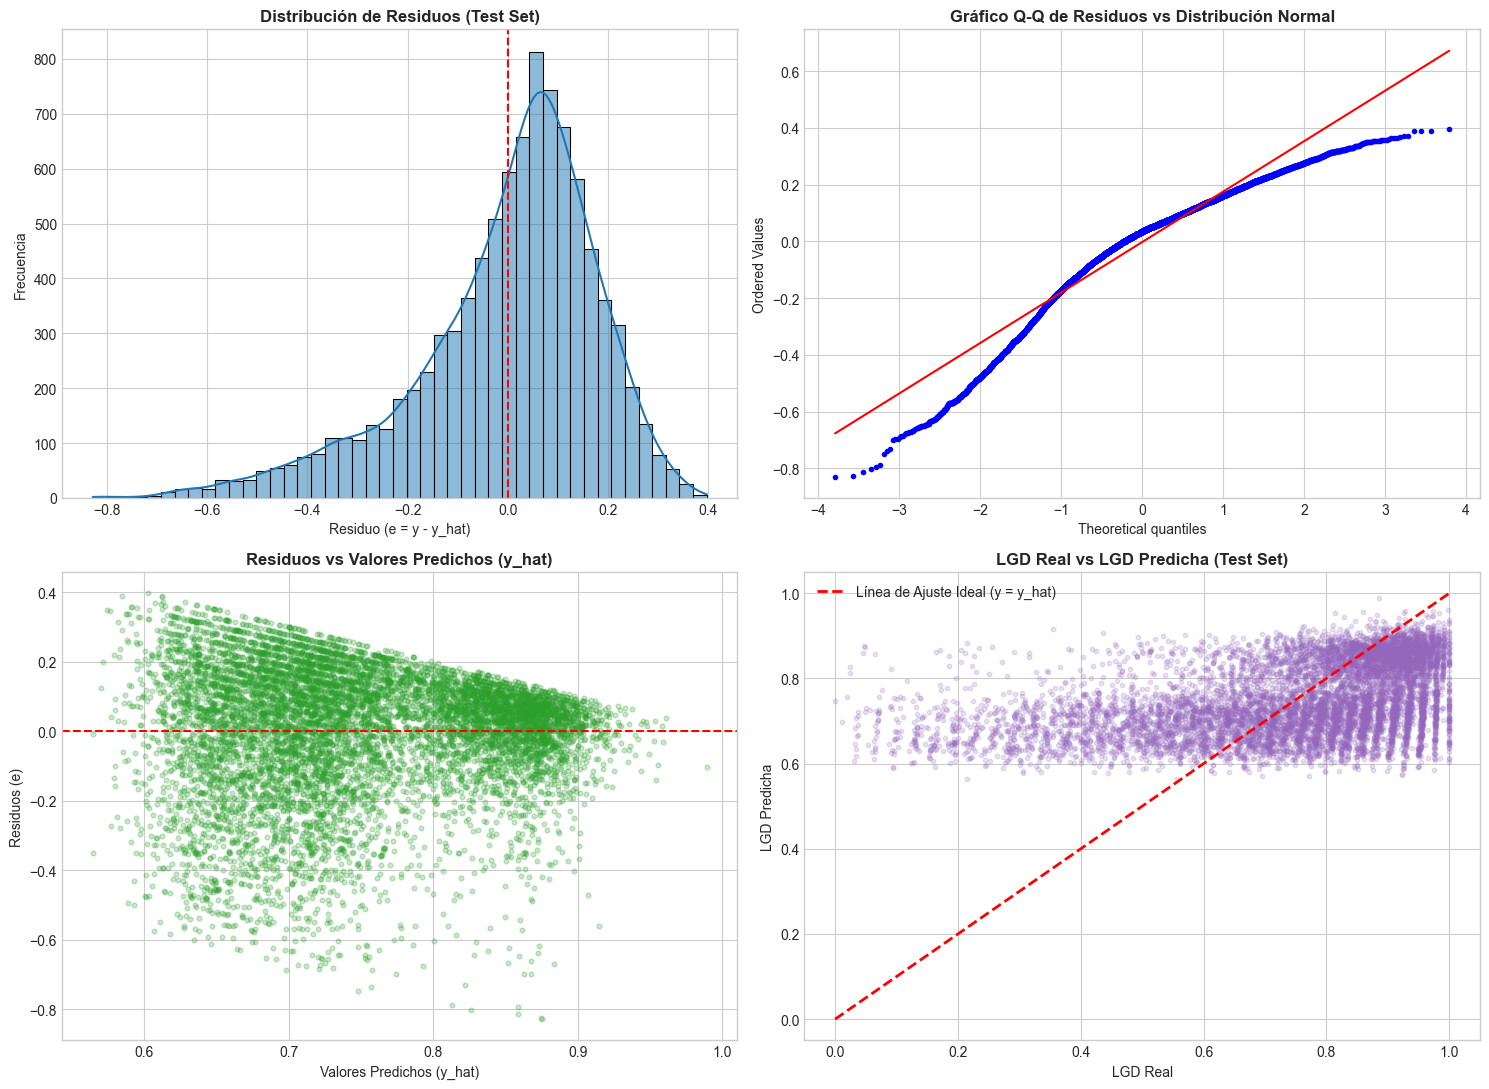

In [8]:
# Gráficos de diagnóstico del error
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Distribución del Error vs Normal Teórica
sns.histplot(residuos_test, bins=45, kde=True, color='#1f77b4', ax=axes[0, 0])
axes[0, 0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0, 0].set_title('Distribución de Residuos (Test Set)', fontweight='bold')
axes[0, 0].set_xlabel('Residuo (e = y - y_hat)')
axes[0, 0].set_ylabel('Frecuencia')

# 2. Gráfico Q-Q (Normal Probability Plot)
stats.probplot(residuos_test, dist='norm', plot=axes[0, 1])
axes[0, 1].set_title('Gráfico Q-Q de Residuos vs Distribución Normal', fontweight='bold')
axes[0, 1].get_lines()[0].set_markersize(3)
axes[0, 1].get_lines()[1].set_color('red')

# 3. Residuos vs Valores Predichos (Diagnóstico de Homocedasticidad)
axes[1, 0].scatter(y_pred_test, residuos_test, alpha=0.25, color='#2ca02c', s=12)
axes[1, 0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1, 0].set_title('Residuos vs Valores Predichos (y_hat)', fontweight='bold')
axes[1, 0].set_xlabel('Valores Predichos (y_hat)')
axes[1, 0].set_ylabel('Residuos (e)')

# 4. Valores Reales vs Predichos
axes[1, 1].scatter(y_test, y_pred_test, alpha=0.2, color='#9467bd', s=10)
axes[1, 1].plot([0, 1], [0, 1], 'r--', linewidth=2, label='Línea de Ajuste Ideal (y = y_hat)')
axes[1, 1].set_title('LGD Real vs LGD Predicha (Test Set)', fontweight='bold')
axes[1, 1].set_xlabel('LGD Real')
axes[1, 1].set_ylabel('LGD Predicha')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

--- 
### 7. Discusión de Resultados y Conclusiones del Estudio Lineal

1. **Significancia de los Parámetros:**
   - **Efecto del Plazo:** La variable indicadora $I_{term60}$ es altamente significativa ($t = 45.81$, $p < 0.001$), aportando aproximadamente $+10.08$ puntos porcentuales directos a la pérdida esperada respecto a los 36 meses.
   - **Efecto de la Calificación:** Todas las variables indicadoras de grado ($I_{grade\_B}$ hasta $I_{grade\_FG}$) presentan coeficientes positivos, crecientes y estrictamente significativos respecto al Grado A base ($p < 0.001$). El Grado FG tiene el mayor incremento ($+15.19$ puntos porcentuales respecto al Grado A).
   - **Apalancamiento ($dti$):** El ratio deuda/ingreso es significativo con efecto positivo ($t = 18.66$, $p < 0.001$).
   - **Variable no significativa:** $funded\_amnt\_k$ y $inq\_6m$ no resultaron significativas una vez controladas las variables de grado, plazo e ingresos ($p > 0.05$).

2. **Bondad de Ajuste y Métricas:**
   - El modelo explica aproximadamente el **17.7% de la varianza** de la severidad de pérdida ($R^2 = 0.177$). Esto es consistente con la literatura empírica de LGD para créditos de consumo no garantizados, donde la severidad de pérdida tiene una alta componente de aleatoriedad individual.
   - El error absoluto medio ($MAE$) es de aproximadamente $0.145$ (un error promedio de 14.5 puntos porcentuales en la estimación de la severidad).

3. **Diagnóstico de los Errores:**
   - La prueba de **Breusch-Pagan** y el gráfico de residuos muestran presencia de heterocedasticidad, y la prueba de **Jarque-Bera** confirma que los residuos se apartan de la normalidad teórica estricta debido a la bimodalidad natural del LGD (acumulación de pérdidas en 1.0).
   - La prueba de **Durbin-Watson** ($pprox 2.0$) confirma independencia serial de los residuos (no-autocorrelación).

4. **Efecto del Acotamiento Económico:**
   - Al evaluar las predicciones de OLS sobre la muestra de créditos en incumplimiento, el rango predicho se situó naturalmente entre $0.564$ y $0.989$, sin generar predicciones menores a 0 ni mayores a 1. Esto se debe a que el modelo lineal capturó que la pérdida condicional al default es consistentemente superior al 50%.
   - Por ende, el acotamiento manual no modifica las métricas en este tramo, mientras que el modelo **GLM Fraccional (Logit)** introduce una compresión sigmoidal suave similar a la activación que tendrá la futura red neuronal multicapa.
